In [255]:
import numpy as np
import pandas as pd
import os 
import matplotlib.pyplot as plt

In [256]:
dict_polymers = pd.read_csv('../dict_polymers.csv')
del dict_polymers['Unnamed: 0']
flopp_table = pd.read_csv('../processed_data/df_flopp.csv').groupby(['file_name', 'polymer']).count().reset_index().iloc[:,:2] #pd.read_csv('../processed_data/flopp_flopp_e_pivot.csv')
#del flopp_flopp_e_table['Unnamed: 0']
dict_polymers = dict_polymers.drop(2, axis=0)

table_poly = flopp_table.merge(dict_polymers, on='polymer', how='left')
table_poly['file_name'] = [name[:-4] for name in table_poly['file_name']]

In [257]:
adaptive_labels = np.array(['Cotton', 'Polyethylene', 'Polyethylene Terephthalate', 'Polypropylene', 'Polystyrene'])

In [258]:
adaptive_labels

array(['Cotton', 'Polyethylene', 'Polyethylene Terephthalate',
       'Polypropylene', 'Polystyrene'], dtype='<U26')

In [259]:
dict_polymers

,pol_short_names,polymer
0,ABS,Acrylonitrile Butadiene Styrene
1,Acrylic,Acrylic
3,CA,Cellulose Acetate
4,Cotton,Cotton
5,EAA,Ethylene Acrylic Acid
6,EVA,Polyethylene Vinyl Acetate
7,Nylon,Nylon
8,PA,Polyamide
9,PBT,Polybutylene Terephthalate
10,PC,Polycarbonate


In [260]:
path = 'Spectral Window and Optimized Corrections/PE/'
files = os.listdir(path)

In [186]:
for i, f in enumerate(files):
    print(i,f)
    table = (pd.read_csv(path + f).sort_values(by='HQI', ascending=False).
             query('HQI > 70').
             merge(table_poly, left_on='Name', right_on='file_name',how='left').
             loc[:, ['HQI', 'pol_short_names']])

    labels = np.unique(table['pol_short_names'])
    n_labels = np.unique(table['pol_short_names']).shape[0]

    table_mean = table.groupby('pol_short_names').mean().T
    table_mean.columns = [l + ' Avg' for l in labels]

    table_std = (table.groupby('pol_short_names').std().T)
    table_std.columns = [l + ' Std D' for l in labels]
    
    #table_max = (table.groupby('pol_short_names').max().T)
    #table_max.columns = [l + ' Top' for l in labels]

    table_n = (table.groupby('pol_short_names').count().T)
    table_n.columns = [l + ' #' for l in labels]

    row = pd.concat([table_mean, table_std, table_n], 1)
    row['0 Entries >= 70'] = table.shape[0]
    row['1 Labels'] = n_labels
    if n_labels > 0:
        row['2 Top Label'] = table.iloc[0,1]
        row['3 Top HQI'] = table.iloc[0,0]
    
    row.index = [f]
    if i == 0:
        table_res = row
    else:
        table_res = pd.concat([table_res, row], 0)
table_res = table_res.loc[:, np.sort(table_res.columns)]

0 PE49_Floppe_correlation_hit_list_corrections_inclusion.csv
1 PE7_Floppe_correlation_hit_list_corrections_inclusion.csv
2 PE43_Floppe_correlation_hit_list_corrections_inclusion.csv
3 PE10_Floppe_correlation_hit_list_corrections_inclusion.csv
4 PE35_Floppe_correlation_hit_list_corrections_inclusion.csv
5 PE21_Floppe_correlation_hit_list_corrections_inclusion.csv
6 PE18_Floppe_correlation_hit_list_corrections_inclusion.csv
7 PE29_Floppe_correlation_hit_list_corrections_inclusion.csv
8 PE5_Floppe_correlation_hit_list_corrections_inclusion.csv
9 PE41_Floppe_correlation_hit_list_corrections_inclusion.csv
10 PE12_Floppe_correlation_hit_list_corrections_inclusion.csv
11 PE37_Floppe_correlation_hit_list_corrections_inclusion.csv
12 PE23_Floppe_correlation_hit_list_corrections_inclusion.csv
13 PE9_Floppe_correlation_hit_list_corrections_inclusion.csv
14 PE47_Floppe_correlation_hit_list_corrections_inclusion.csv
15 PE3_Floppe_correlation_hit_list_corrections_inclusion.csv
16 PE25_Floppe_correla

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean

31 PE38_Floppe_correlation_hit_list_corrections_inclusion.csv
32 PE32_Floppe_correlation_hit_list_corrections_inclusion.csv
33 PE26_Floppe_correlation_hit_list_corrections_inclusion.csv
34 PE17_Floppe_correlation_hit_list_corrections_inclusion.csv
35 PE44_Floppe_correlation_hit_list_corrections_inclusion.csv
36 PE48_Floppe_correlation_hit_list_corrections_inclusion.csv
37 PE11_Floppe_correlation_hit_list_corrections_inclusion.csv
38 PE20_Floppe_correlation_hit_list_corrections_inclusion.csv
39 PE34_Floppe_correlation_hit_list_corrections_inclusion.csv
40 PE6_Floppe_correlation_hit_list_corrections_inclusion.csv
41 PE42_Floppe_correlation_hit_list_corrections_inclusion.csv
42 PE19_Floppe_correlation_hit_list_corrections_inclusion.csv
43 PE28_Floppe_correlation_hit_list_corrections_inclusion.csv
44 PE13_Floppe_correlation_hit_list_corrections_inclusion.csv
45 PE22_Floppe_correlation_hit_list_corrections_inclusion.csv
46 PE36_Floppe_correlation_hit_list_corrections_inclusion.csv
47 PE4_Fl

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([tabl

In [187]:
table_res.to_csv('knowItAll_PE.csv')

In [231]:
for i, f in enumerate(files):
    print(i,f)
    table = (pd.read_csv(path + f).sort_values(by='HQI', ascending=False).
             query('HQI > 70').
             merge(table_poly, left_on='Name', right_on='file_name',how='left').
             query('polymer in @adaptive_labels').
             loc[:, ['HQI', 'pol_short_names']])

    labels = np.unique(table['pol_short_names'])
    n_labels = np.unique(table['pol_short_names']).shape[0]

    table_mean = table.groupby('pol_short_names').mean().T
    table_mean.columns = [l + ' Avg' for l in labels]

    table_std = (table.groupby('pol_short_names').std().T)
    table_std.columns = [l + ' Std D' for l in labels]
    
    #table_max = (table.groupby('pol_short_names').max().T)
    #table_max.columns = [l + ' Top' for l in labels]

    table_n = (table.groupby('pol_short_names').count().T)
    table_n.columns = [l + ' #' for l in labels]

    row = pd.concat([table_mean, table_std, table_n], 1)
    row['0 Entries >= 70'] = table.shape[0]
    row['1 Labels'] = n_labels
    if n_labels > 0:
        row['2 Top Label'] = table.iloc[0,1]
        row['3 Top HQI'] = table.iloc[0,0]
    
    row.index = [f]
    if i == 0:
        table_res = row
    else:
        table_res = pd.concat([table_res, row], 0)
table_res = table_res.loc[:, np.sort(table_res.columns)]
table_res.to_csv('knowItAll_PE_adaptive.csv')

0 PE49_Floppe_correlation_hit_list_corrections_inclusion.csv
1 PE7_Floppe_correlation_hit_list_corrections_inclusion.csv
2 PE43_Floppe_correlation_hit_list_corrections_inclusion.csv
3 PE10_Floppe_correlation_hit_list_corrections_inclusion.csv
4 PE35_Floppe_correlation_hit_list_corrections_inclusion.csv
5 PE21_Floppe_correlation_hit_list_corrections_inclusion.csv
6 PE18_Floppe_correlation_hit_list_corrections_inclusion.csv
7 PE29_Floppe_correlation_hit_list_corrections_inclusion.csv
8 PE5_Floppe_correlation_hit_list_corrections_inclusion.csv
9 PE41_Floppe_correlation_hit_list_corrections_inclusion.csv
10 PE12_Floppe_correlation_hit_list_corrections_inclusion.csv
11 PE37_Floppe_correlation_hit_list_corrections_inclusion.csv
12 PE23_Floppe_correlation_hit_list_corrections_inclusion.csv
13 PE9_Floppe_correlation_hit_list_corrections_inclusion.csv
14 PE47_Floppe_correlation_hit_list_corrections_inclusion.csv
15 PE3_Floppe_correlation_hit_list_corrections_inclusion.csv
16 PE25_Floppe_correla

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean

28 PE15_Floppe_correlation_hit_list_corrections_inclusion.csv
29 PE46_Floppe_correlation_hit_list_corrections_inclusion.csv
30 PE2_Floppe_correlation_hit_list_corrections_inclusion.csv
31 PE38_Floppe_correlation_hit_list_corrections_inclusion.csv
32 PE32_Floppe_correlation_hit_list_corrections_inclusion.csv
33 PE26_Floppe_correlation_hit_list_corrections_inclusion.csv
34 PE17_Floppe_correlation_hit_list_corrections_inclusion.csv
35 PE44_Floppe_correlation_hit_list_corrections_inclusion.csv
36 PE48_Floppe_correlation_hit_list_corrections_inclusion.csv
37 PE11_Floppe_correlation_hit_list_corrections_inclusion.csv
38 PE20_Floppe_correlation_hit_list_corrections_inclusion.csv
39 PE34_Floppe_correlation_hit_list_corrections_inclusion.csv
40 PE6_Floppe_correlation_hit_list_corrections_inclusion.csv
41 PE42_Floppe_correlation_hit_list_corrections_inclusion.csv
42 PE19_Floppe_correlation_hit_list_corrections_inclusion.csv
43 PE28_Floppe_correlation_hit_list_corrections_inclusion.csv
44 PE13_Fl

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/1724480591.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([tabl

In [234]:
path = 'Spectral Window and Optimized Corrections/PP/'
files = os.listdir(path)

In [189]:
for i, f in enumerate(files):
    print(i,f)
    table = (pd.read_csv(path + f).sort_values(by='HQI', ascending=False).
             query('HQI > 70').
             merge(table_poly, left_on='Name', right_on='file_name',how='left').
             loc[:, ['HQI', 'pol_short_names']])

    labels = np.unique(table['pol_short_names'])
    n_labels = np.unique(table['pol_short_names']).shape[0]

    table_mean = table.groupby('pol_short_names').mean().T
    table_mean.columns = [l + ' Avg' for l in labels]

    table_std = (table.groupby('pol_short_names').std().T)
    table_std.columns = [l + ' Std D' for l in labels]
    
    #table_max = (table.groupby('pol_short_names').max().T)
    #table_max.columns = [l + ' Top' for l in labels]

    table_n = (table.groupby('pol_short_names').count().T)
    table_n.columns = [l + ' #' for l in labels]

    row = pd.concat([table_mean, table_std, table_n], 1)
    row['0 Entries >= 70'] = table.shape[0]
    row['1 Labels'] = n_labels
    if n_labels > 0:
        row['2 Top Label'] = table.iloc[0,1]
        row['3 Top HQI'] = table.iloc[0,0]
    
    row.index = [f]
    if i == 0:
        table_res = row
    else:
        table_res = pd.concat([table_res, row], 0)
table_res = table_res.loc[:, np.sort(table_res.columns)]

0 PP66_Floppe_correlation_hit_list_corrections_inclusion.csv
1 PP43_Floppe_correlation_hit_list_corrections_inclusion.csv
2 PP57_Floppe_correlation_hit_list_corrections_inclusion.csv
3 PP10_Floppe_correlation_hit_list_corrections_inclusion.csv
4 PP21_Floppe_correlation_hit_list_corrections_inclusion.csv
5 PP35_Floppe_correlation_hit_list_corrections_inclusion.csv
6 PP49_Floppe_correlation_hit_list_corrections_inclusion.csv
7 PP64_Floppe_correlation_hit_list_corrections_inclusion.csv
8 PP41_Floppe_correlation_hit_list_corrections_inclusion.csv
9 PP55_Floppe_correlation_hit_list_corrections_inclusion.csv
10 PP12_Floppe_correlation_hit_list_corrections_inclusion.csv
11 PP2_Floppe_correlation_hit_list_corrections_inclusion.csv
12 PP23_Floppe_correlation_hit_list_corrections_inclusion.csv
13 PP37_Floppe_correlation_hit_list_corrections_inclusion.csv
14 PP18_Floppe_correlation_hit_list_corrections_inclusion.csv
15 PP8_Floppe_correlation_hit_list_corrections_inclusion.csv
16 PP29_Floppe_corre

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean

29 PP27_Floppe_correlation_hit_list_corrections_inclusion.csv
30 PP6_Floppe_correlation_hit_list_corrections_inclusion.csv
31 PP16_Floppe_correlation_hit_list_corrections_inclusion.csv
32 PP39_Floppe_correlation_hit_list_corrections_inclusion.csv
33 PP24_Floppe_correlation_hit_list_corrections_inclusion.csv
34 PP30_Floppe_correlation_hit_list_corrections_inclusion.csv
35 PP15_Floppe_correlation_hit_list_corrections_inclusion.csv
36 PP5_Floppe_correlation_hit_list_corrections_inclusion.csv
37 PP46_Floppe_correlation_hit_list_corrections_inclusion.csv
38 PP52_Floppe_correlation_hit_list_corrections_inclusion.csv
39 PP63_Floppe_correlation_hit_list_corrections_inclusion.csv
40 PP58_Floppe_correlation_hit_list_corrections_inclusion.csv
41 PP26_Floppe_correlation_hit_list_corrections_inclusion.csv
42 PP32_Floppe_correlation_hit_list_corrections_inclusion.csv
43 PP7_Floppe_correlation_hit_list_corrections_inclusion.csv
44 PP17_Floppe_correlation_hit_list_corrections_inclusion.csv
45 PP44_Flo

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([tabl

61 PP54_Floppe_correlation_hit_list_corrections_inclusion.csv
62 PP40_Floppe_correlation_hit_list_corrections_inclusion.csv
63 PP19_Floppe_correlation_hit_list_corrections_inclusion.csv
64 PP9_Floppe_correlation_hit_list_corrections_inclusion.csv
65 PP28_Floppe_correlation_hit_list_corrections_inclusion.csv


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:23: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/2335681789.py:34: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([tabl

In [190]:
table_res.to_csv('knowItAll_PP.csv')

In [235]:
for i, f in enumerate(files):
    print(i,f)
    table = (pd.read_csv(path + f).sort_values(by='HQI', ascending=False).
             query('HQI > 70').
             merge(table_poly, left_on='Name', right_on='file_name',how='left').
             query('polymer in @adaptive_labels').
             loc[:, ['HQI', 'pol_short_names']])

    labels = np.unique(table['pol_short_names'])
    n_labels = np.unique(table['pol_short_names']).shape[0]

    table_mean = table.groupby('pol_short_names').mean().T
    table_mean.columns = [l + ' Avg' for l in labels]

    table_std = (table.groupby('pol_short_names').std().T)
    table_std.columns = [l + ' Std D' for l in labels]
    
    #table_max = (table.groupby('pol_short_names').max().T)
    #table_max.columns = [l + ' Top' for l in labels]

    table_n = (table.groupby('pol_short_names').count().T)
    table_n.columns = [l + ' #' for l in labels]

    row = pd.concat([table_mean, table_std, table_n], 1)
    row['0 Entries >= 70'] = table.shape[0]
    row['1 Labels'] = n_labels
    if n_labels > 0:
        row['2 Top Label'] = table.iloc[0,1]
        row['3 Top HQI'] = table.iloc[0,0]
    
    row.index = [f]
    if i == 0:
        table_res = row
    else:
        table_res = pd.concat([table_res, row], 0)
table_res = table_res.loc[:, np.sort(table_res.columns)]
table_res.to_csv('knowItAll_PP_adaptive.csv')

0 PP66_Floppe_correlation_hit_list_corrections_inclusion.csv
1 PP43_Floppe_correlation_hit_list_corrections_inclusion.csv
2 PP57_Floppe_correlation_hit_list_corrections_inclusion.csv
3 PP10_Floppe_correlation_hit_list_corrections_inclusion.csv
4 PP21_Floppe_correlation_hit_list_corrections_inclusion.csv
5 PP35_Floppe_correlation_hit_list_corrections_inclusion.csv
6 PP49_Floppe_correlation_hit_list_corrections_inclusion.csv
7 PP64_Floppe_correlation_hit_list_corrections_inclusion.csv
8 PP41_Floppe_correlation_hit_list_corrections_inclusion.csv
9 PP55_Floppe_correlation_hit_list_corrections_inclusion.csv
10 PP12_Floppe_correlation_hit_list_corrections_inclusion.csv
11 PP2_Floppe_correlation_hit_list_corrections_inclusion.csv
12 PP23_Floppe_correlation_hit_list_corrections_inclusion.csv
13 PP37_Floppe_correlation_hit_list_corrections_inclusion.csv
14 PP18_Floppe_correlation_hit_list_corrections_inclusion.csv
15 PP8_Floppe_correlation_hit_list_corrections_inclusion.csv
16 PP29_Floppe_corre

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, ta

28 PP33_Floppe_correlation_hit_list_corrections_inclusion.csv
29 PP27_Floppe_correlation_hit_list_corrections_inclusion.csv
30 PP6_Floppe_correlation_hit_list_corrections_inclusion.csv
31 PP16_Floppe_correlation_hit_list_corrections_inclusion.csv
32 PP39_Floppe_correlation_hit_list_corrections_inclusion.csv
33 PP24_Floppe_correlation_hit_list_corrections_inclusion.csv
34 PP30_Floppe_correlation_hit_list_corrections_inclusion.csv
35 PP15_Floppe_correlation_hit_list_corrections_inclusion.csv
36 PP5_Floppe_correlation_hit_list_corrections_inclusion.csv
37 PP46_Floppe_correlation_hit_list_corrections_inclusion.csv
38 PP52_Floppe_correlation_hit_list_corrections_inclusion.csv
39 PP63_Floppe_correlation_hit_list_corrections_inclusion.csv
40 PP58_Floppe_correlation_hit_list_corrections_inclusion.csv
41 PP26_Floppe_correlation_hit_list_corrections_inclusion.csv
42 PP32_Floppe_correlation_hit_list_corrections_inclusion.csv
43 PP7_Floppe_correlation_hit_list_corrections_inclusion.csv
44 PP17_Flo

/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_re

60 PP65_Floppe_correlation_hit_list_corrections_inclusion.csv
61 PP54_Floppe_correlation_hit_list_corrections_inclusion.csv
62 PP40_Floppe_correlation_hit_list_corrections_inclusion.csv
63 PP19_Floppe_correlation_hit_list_corrections_inclusion.csv
64 PP9_Floppe_correlation_hit_list_corrections_inclusion.csv
65 PP28_Floppe_correlation_hit_list_corrections_inclusion.csv


/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_res, row], 0)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:24: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  row = pd.concat([table_mean, table_std, table_n], 1)
/var/folders/9g/bj6gc6z17_1fyb7lx57xf04m0000gs/T/ipykernel_9572/833548050.py:35: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only.
  table_res = pd.concat([table_re

In [248]:
x = np.linspace(-5,5)
def expit(x):
    return 1 / (1 + np.exp(-x))
y = expit(x)

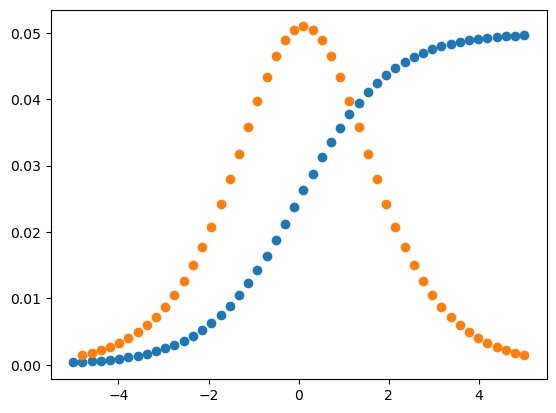

In [254]:
plt.scatter(x, y/20)
plt.scatter(x[1:],np.diff(y))